# Robot Learning
## Exercise 1

2026
TAs: Andrea Protopapa (andrea.protopapa@polito.it), Davide Buoso (davide.buoso@polito.it)

# 1. Introduction
Throughout this exercise session, we will take a first look at a Reinforcement Learning environment and its components. In particular, we will deal with the Cart-Pole environment, a classic problem in Reinforcement Learning. Our primary goal is to implement and evaluate various control strategies, including a Linear Quadratic Regulator (LQR) baseline or random policies, to understand their impact on the system's performance and learn about the fundamental concepts of Reinforcement Learning, laying the groundwork for more advanced reinforcement learning techniques in subsequent exercises.

To proceed with the assignment, visit the dedicated starting code at the dedicated webpage and follow the steps listed below in this document. Note: if you haven’t joined the course’s github classroom yet, you will be asked to select your name when you visit it the first time.

As you follow the steps in this document, make sure you’re able to answer all the guiding questions listed at the end of each step.


# 2. Cartpole Gym environment: states, observations

The Cartpole environment consists of a cart and a pole mounted on top of it, as shown in Figure 1. The cart can move either to the left or to the right. The goal is to balance the pole in a vertical position in order to prevent it from falling down. The cart should also stay within a limited distance from the center (trying to move outside screen boundaries is considered a failure).
The observation is a four element vector:





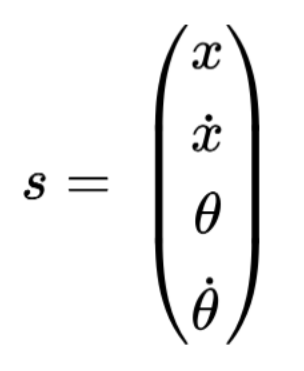

where  is the position of the cart,  is its velocity,  is the angle of the pole w.r.t. the vertical axis, and  is
the angular velocity of the pole.

Gym environment documentation:  https://gymnasium.farama.org/environments/classic_control/cart_pole/


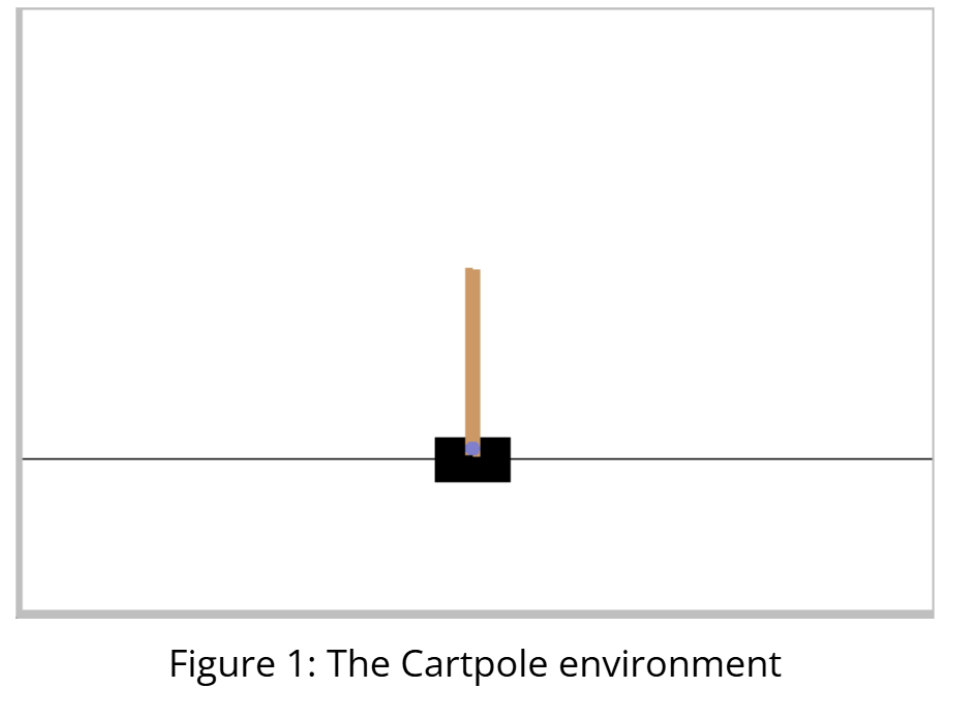

# 3. LQR
For the first assignment, you are tasked with testing a baseline using a Linear Quadratic Regulator (LQR), resulting in an optimal control gain K. The baseline is already implemented in the provided Python script (cartpole_lqr.py). Since the system exhibits nonlinear dynamics, a linear approximation of the system is available through the linearized_cartpole_system(...) function. Given the linear state space representation, the controller K is optimized by minimizing the following cost function:

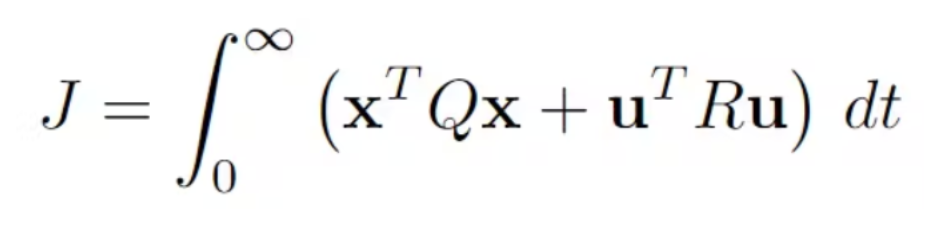

where Q and R are weight matrices carefully chosen and designed. The Q matrix represents the gain of the cost function on the states of the system, while the R matrix represents the gain of the cost function on the input to the system. Therefore, Q and R define what we consider as optimal.



## Task 1
Plot the states of the system (i.e., the elements of the observation vector) over the first 1000 timesteps. Remember that the Cart-Pole task is considered solved by Gym when 499 time steps are reached without the pole falling over.



### Question 1  
Looking at the plot, after which timestep do all states converge to within 0 ± 0.003? Explain what it means for all states to converge to zero from a control standpoint.

### Answer 1:

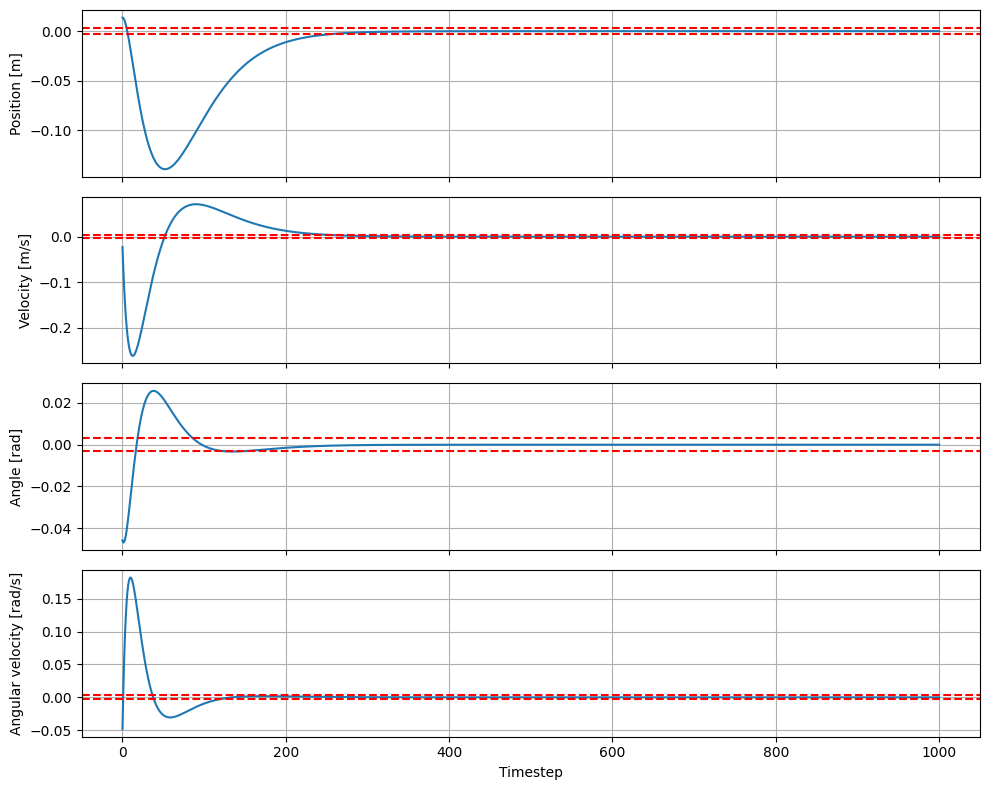

All four states converge to within ±0.003 after **263 timesteps** and remain within this tolerance for the rest of the simulation. From a control perspective, convergence to zero means that the LQR controller successfully stabilizes the system around its desired equilibrium: the cart returns to the center, the pole becomes upright, and both linear and angular velocities approach zero. This demonstrates successful regulation after the initial transient response.

## Task 2:
Vary the value of R within the range [0.01, 0.1, 10, 100] and plot the forces applied to each of the four controlled systems in a single graph over the first 500 timesteps.

*Note 1: for a better visual comparison, invert the single plot for each value of R if the first force applied on the cartpole is positive (e.g., if you are storing all the forces in an array called forces,
this means forces[0]>0). In this way, all the plots would have the same trend*.

Note 2: To ensure the experiments are comparable, you should recreate the environment for each R value. Otherwise, before resetting the environment, reset the seed.

```
		set_seed(args.seed) # seed for reproducibility
		env.env.seed(args.seed)
		# …
		env.reset()
```



### Question 1:
 Analyzing the plot, how does the choice of R affect the force? Are they proportional or inversely proportional?


### Answer 1:

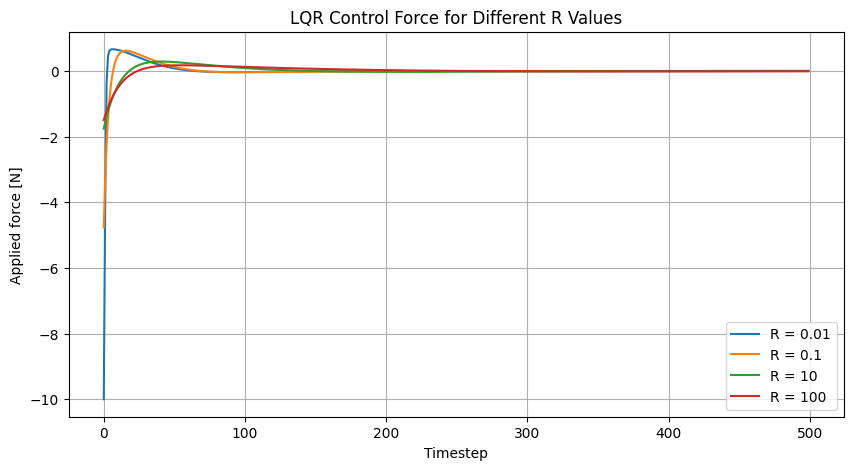

The applied control force generally decreases in magnitude as the value of \(R\) increases, indicating an inverse relationship between \(R\) and control effort. This occurs because \(R\) penalizes the control input in the LQR cost function. Smaller values of \(R\) allow more aggressive control actions, whereas larger values produce less aggressive corrections. For \(R=0.01\), the initial force reaches the saturation limit of −10 N, while for \(R=100\), the initial force is approximately −1.4 N. However, this relationship is not strictly inversely proportional because the optimal feedback gain depends nonlinearly on \(R\).

# 4. Reinforcement Learning
The provided Python script (cartpole_rl.py) instantiates a Cartpole environment and a RL agent that acts on it. The agent.py file contains the implementation of a simple reinforcement learning agent; for the sake of this exercise, you can assume it to be a black box (you don’t need to understand how it works, although you are encouraged to study it in more detail). You don’t have to edit that file to complete this exercise session - all changes should be done in cartpole_rl.py.





## 4.1 Training and testing
Run the cartpole_rl.py script. See how it learns to balance the pole after training for some amount of episodes. You can use the --render_training argument to visualize the training (it will run slower when rendering).
When the training is finished, the models are saved to CartPole-v0_params.ai and can be tested by passing --test <path>/<to>/<model>/<file.ai>. You can use the --render_test argument here.

All the training algorithm is encapsulated within the train(...) function. Examine the training loop and answer the following questions:

### Question 1.0.1
What are the conditions under which the episode ends? Do all episodes conclude at the same timestep?


### Answer 1.0.1:


An episode ends either when the pole exceeds its allowed angle, the cart moves outside its position limits, or the maximum episode length is reached. Therefore, episodes do not necessarily terminate at the same timestep.

### Question 1.0.2
How is the reward internally computed?

*Note: You can refer to the environment's documentation for more details or inspect the code to
determine when different episodes conclude. Rendering the environment may also aid in
understanding episode termination and reward computation.*


### Answer 1.0.2:

The standard CartPole environment provides a reward of +1 for each timestep executed. The total episode reward therefore corresponds to the number of timesteps survived. The agent learns to maximize this reward by balancing the pole for as long as possible.

## Task 1.1.
Try to train the agent using a random policy. This entails not considering the predicted actions by the agent at each current timestep. Instead, sample a random action from within the action space, and perform this action on the environment.

### Question 1.1
Evaluate the learned random policy. What is the performance in terms of the average test reward compared to training with the normal policy? Briefly analyze the underlying causes.


### Answer 1.1:

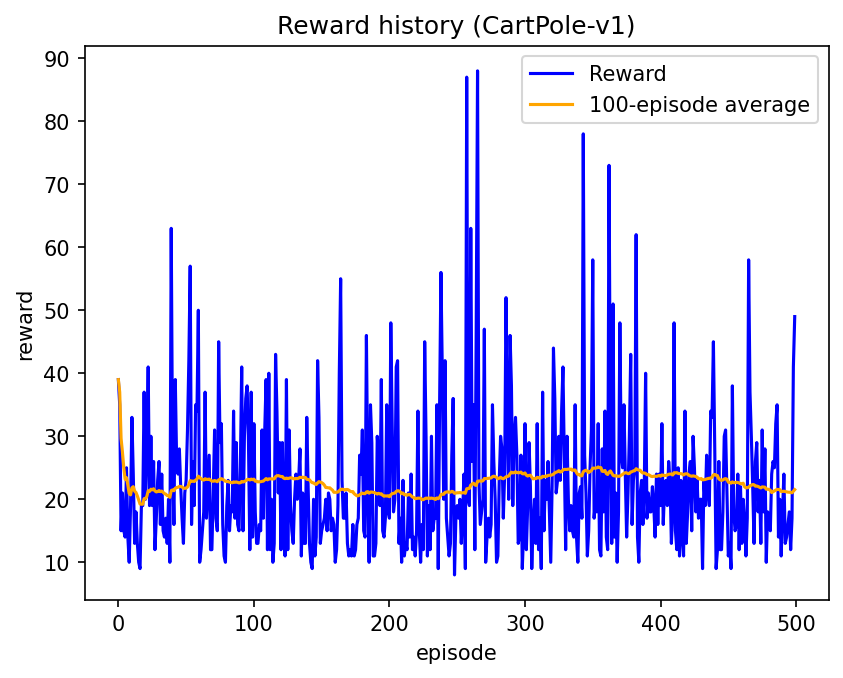

In [ ]:
/content/exercise1-rl-fundamentals-RL2026
=== Normal RL Policy ===
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_normal_params.ai ...
Testing...
Num testing episodes: 20
Average test reward: 500.0 episode length: 500.0

=== Random-Action Training ===
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_random_params.ai ...
Testing...
Num testing episodes: 20
Average test reward: 151.45 episode length: 151.45

The agent trained with the normal RL policy achieved an average test reward of **500**, compared to **151.45** for the agent trained with random actions, over 20 evaluation episodes. The normal policy achieved the maximum possible reward, demonstrating successful control of the CartPole system. Random-action training performed significantly worse because actions were selected independently of the learned policy, preventing effective policy improvement. Therefore, the normal RL training method produces a more reliable controller.

## Task 1.2
Train the agent using the Reinforcement Learning policy with up to 200 timesteps per episode. First, tune the learning rate hyperparameter, as this can have a significant impact on the policy's performance. Try values from the following range:

[1e-5, 1e-4, 1e-3, 1e-2, 1e-1].

### Question 1.2:
Which learning rate value provides the best, most stable performance? Can you explain why?

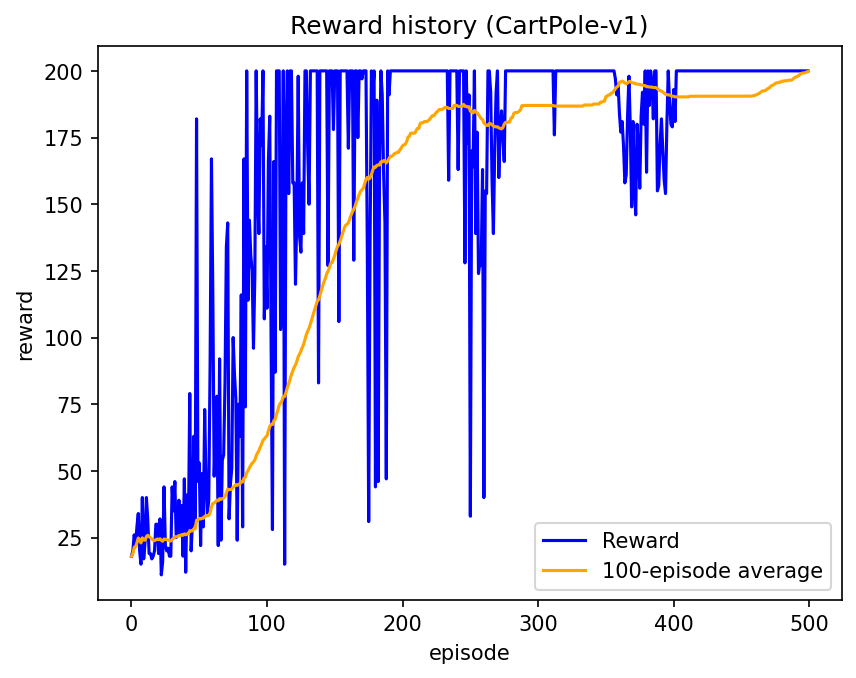


The learning rate $\alpha = 10^{-2}$ provided the best overall performance and stability in our experiments.

Smaller learning rates ($10^{-5}$, $10^{-4}$, and $10^{-3}$) resulted in slow or negligible learning, with average rewards remaining around 20–25 after 500 training episodes.

A larger learning rate ($10^{-1}$) eventually achieved high rewards but produced significant fluctuations and slower convergence.

Therefore, $\alpha = 10^{-2}$ provided the best balance between sufficiently large policy updates for efficient learning and sufficiently controlled updates for stable performance.

These conclusions are based on single training runs and may vary with the random seed.


## Task 1.3
Then test the model for 500 timesteps by
changing line n.138 in cartpole_rl.py. You can test the model with:


```
python cartpole_rl.py -t <MODELFILE> --render_test
```

<br>

*Note: the episode length and the number of episodes given by the command line argument
train_episodes are two different things. If you include plots in your submission, use the
train_episodes  as their x-axis.*


### Question 1.3:
Can the same model, trained to balance for 200 timesteps, also balance the pole
for 500 timesteps? Briefly justify your answer.


### Answer 1.3:

In [ ]:
/content/exercise1-rl-fundamentals-RL2026
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from model_lr_1e-2.ai ...
Testing...
Num testing episodes: 20
Average test reward: 355.65 episode length: 355.65


Yes, the agent trained with a maximum episode length of 200 timesteps can maintain balance for longer periods. When evaluated over 20 episodes with a maximum length of 500 timesteps, the model achieved an average test reward of **355.65**.

This indicates that the learned policy can operate beyond its original training horizon because it selects actions based on the current system state rather than following a fixed-length sequence. However, since the average reward remains below 500, the agent does not consistently maintain balance for the entire testing duration.

## Task 1.4:
 Repeat the experiment a few times, each time training the model from scratch with 200
timesteps and testing it for 500 timesteps. Evaluate its performance by using the --render_test argument and remember the average test rewards.


### Question 1.4:
Are the behavior and performance of the trained model the same every time?
Analyze the causes briefly.


### Answer 1.4:

The behavior and performance of the trained model are not the same across independent training runs. Using identical hyperparameters, three independently trained agents achieved average test rewards of **355.65**, **159.85**, and **201.90**, respectively.

This variation is primarily caused by the stochastic nature of reinforcement learning, including random neural-network initialization, randomized initial environment states, and probabilistic action selection during training. These factors produce different experiences and policy updates, leading to different final controllers. Therefore, a single training run is insufficient to reliably evaluate an RL algorithm, and performance should be assessed across multiple independent runs.

# 4.2 Repeatability

Figure 2 shows the mean and standard deviation throughout 100 independent training procedures. You can notice that there is a large variance between the runs of the script.

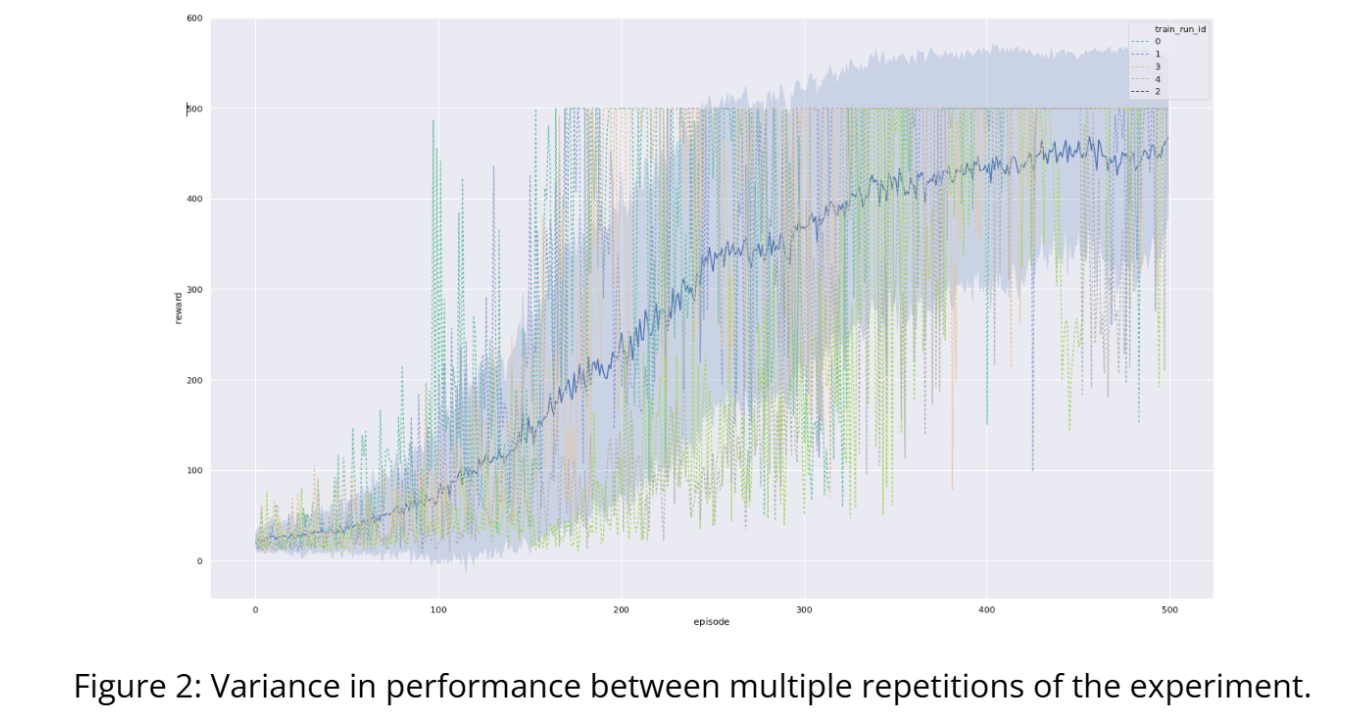

### Question 2:
Why is this the case? What are the implications of this stochasticity, when it comes to comparing reinforcement learning algorithms to each other? Please explain.

*Note: You can generate a similar plot by running the multiple_cartpoles_rl.py script. If the script is slow, try disabling PyTorch multithreading (by running the script with OMP_NUM_THREADS=1)*



### Answer 2:

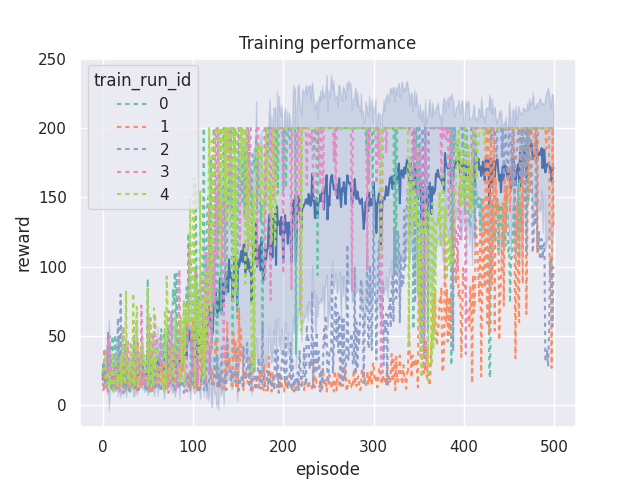

The performance varies significantly across independent training runs because reinforcement learning is stochastic. Random neural-network initialization, different initial environment states, and probabilistic action selection lead to different experiences and policy updates. Consequently, some agents learn much faster than others, even when using identical hyperparameters.

This variability is visible in our experiment with 10 independent training runs. Some agents reached the maximum reward relatively early, while others converged later or experienced significant performance fluctuations.

When comparing RL algorithms, evaluating only one training run is therefore insufficient. We should use multiple independent runs, report the mean performance and standard deviation, and compare algorithms under consistent training conditions and computational budgets. This provides a more reliable assessment of their performance, stability, and reproducibility.

# 4.3 Reward functions:
Let us design a custom reward function and use it instead of the default reward returned by the environment (see the new_reward(...) function for an example).




## Task 3.1
Write different reward functions to incentivise the agent to learn the following behaviors and include them in your report:
1. Balance the pole close to the center of the screen (close to x=0),
2. Balance the pole in an arbitrary point of the screen (x=x0), with x0 passed as a command line argument to the script,
3. Keep the cart moving from the leftmost to rightmost side of the track as fast as possible, while still balancing the pole. The minimum speed of the agent should be high enough that the agent is visibly moving from one side of the other (not just jittering in the center) and changes direction at least once and not just drifting in a random direction.

Train a model with each reward function and include them in your submission.

**Hint**: Use the observation vector to get the quantities required to compute the new reward (such as the
speed and position of the cart). If you feel like your model needs more time to train, you can leave it running for longer with the command line argument --train_episodes number, where number is the amount of episodes the model will be trained for (default is 500).



## Task 3.2
Let us visualize the third reward function. Train the model at least 10 times using
multiple_cartpoles_rl.py (adjust the --num_runs and --train_episodes parameters) and include the performance plots similar to Fig. 2.


### Question 3.2:
Observe the agent using `python cartpole_rl.py -t <MODELFILE> --render_test` and keep track of the observations. What do you observe? What is the highest velocity the agent reaches?



### Answer 3.2

# 5. Extras

### Question 1:
Discuss briefly the advantages of using an LQR controller or an RL agent to solve a general task of controlling a robotic system. Analyze the differences and similarities between the two methods.


### Answer 1:
